<a href="https://colab.research.google.com/github/project-ida/arpa-e-experiments/blob/main/analysis/mastromatteo-03/Mastromatteo_3_PSD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<a href="https://nbviewer.org/github/project-ida/arpa-e-experiments/blob/main/analysis/mastromatteo-03/Mastromatteo_3_PSD.ipynb" target="_parent"><img src="https://nbviewer.org/static/img/nav_logo.svg" alt="Open In nbviewer" width="100"/></a>


‼️ **Prerequisites** ‼️:
- Access to the `Nucleonics` Google drive folder (it must also be added as a shortcut called "Nucleonics" in your own drive)
- Access to the nucleonics `.env` folder (where sensitive info lives)

# PSD Analysis

The analysis notebook relies on the ["Nuclear particle master"](https://docs.google.com/spreadsheets/d/1zgp8MplLXNAI1s7NAs7tCCVnv7N05AR4Q7x4hnE_PiA/edit?gid=0#gid=0) sheet to provide timestamps that allow us to separate the radiation data from experiments into several regions. In ideal experiments, we'll have:
- Set-up
- Calibration (with source)
- Background 1
- Experiment
- Background 2

A PSD plot will be created for the calibration period in order to extract a `psp_threshold` that allows us to discriminate between gammas and neutrons. This threshold is then saved back to the master sheet.



## Running this notebook

Go ahead and change the `experiment_id` and `channel_number` below and then run the whole notebook.

You will be asked a couple of time to authenticate with your Google account, but after that all the analysis will happen automatically.

In [1]:
experiment_id = 12
channel_number = 2

In [ ]:
# Makes Libs accessible and runs notebook from same location regardless of whether colab or local
!pip install colocal -q
import colocal
root, branch, cwd = colocal.setup()

## Libraries

In [2]:
# Auth
import sys, os
import shutil
from google.colab import drive
from google.colab import auth
from google.auth import default

# Interacting with sheets
import gspread

# Data analysis
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from sqlalchemy import create_engine, text

# Plotting
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Use our custom helper functions
from libs.sql_api import SQLConnection, SQLAPIError, read_sql

## Authentication

We need to do a few authentication steps:
- Bring in the database credentials from Google drive so that we can pull data from the live database.
- Bring in the nuclear particle master sheet ID
-  Authenticate Colab to pull the nuclear particle master sheet using the Drive API.

In [3]:
# Mount Drive
drive.mount('/content/drive')

# Copy SQL credentials from Google drive
shutil.copy("/content/drive/MyDrive/Nucleonics/.env/psql_credentials_readonly.py", "psql_credentials.py")

# Copy sheet ID file from Google drive
shutil.copy("/content/drive/MyDrive/Nucleonics/.env/sheet_ids.py", "sheet_ids.py");

Mounted at /content/drive


In [4]:
# Import SQL credentials
from psql_credentials import PGHOST, PGUSER, PGPASSWORD, PGPORT, PGDATABASE

# Import sheet ID for the nuclear particle master sheet
from sheet_ids import NUCLEAR_PARTICLE_MASTER as sheet_id

# Create the database connection string
connection_uri = f'https://{PGHOST}/sql-api/query.php'
engine = SQLConnection(
    connection_uri,
    PGUSER,
    PGPASSWORD,
    database=PGDATABASE,
    timeout=(10, 600),
)

In [5]:

# Authenticate using Colab's built-in credentials
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

## Extracting experimental timestamps

We need to
- Open the master sheet
- Find the row corresponding with the experiment
- Extract the timestamp columns

Because the master sheet is organised in blocks that share an experiment ID (to avoid visual overload) we'll need to "fill in" the experiment ID for all rows once the sheet is brought into a pandas dataframe.



In [6]:
# Fill experiment IDs based on the block organisation of the master sheet
def fill_experiment_id(df):
    experiment_id = None
    updated_ids = []

    for index, row in df.iterrows():
        if pd.notna(row['Experiment ID']) and row['Experiment ID'] != '':
            experiment_id = row['Experiment ID']
        updated_ids.append(experiment_id)

    df['Experiment ID'] = updated_ids
    return df

In [7]:
sheet = gc.open_by_key(sheet_id).sheet1

# Read the sheet into a pandas DataFrame
df = pd.DataFrame(sheet.get_all_records())

# Fill the experiment IDs based on the block organisation of the master sheet
df = fill_experiment_id(df)

In [8]:
# Find the rows where Experiment ID matches
rows = df[df['Experiment ID'] == experiment_id]

if len(rows) == 0:
    raise ValueError(f"No master sheet entry for 'Experiment ID' = {experiment_id}")

# Extract the row corresponding to the specified channel number
row = rows[rows["Digitizer channel number"] == channel_number]

if len(row) == 0:
    raise ValueError(f"No master sheet entry for 'Experiment ID' = {experiment_id}, 'Digitizer channel number' = {channel_number}")

# Extract digitizer for SQL table identification
digitizer = row.iloc[0]["Digitizer"]

# Try to extract times from the channel-specific row
times = row[['Setup', 'Calibration', 'Background 1', 'Experiment', 'Background 2', 'End']]

# If all values are missing/empty, fall back to the first row of the experiment block
if (times.isna() | times.eq('')).all().all():
    times = rows.iloc[[0]][['Setup', 'Calibration', 'Background 1', 'Experiment', 'Background 2', 'End']]

# Convert to datetime
times = times.apply(pd.to_datetime)

# Display the extracted times
times.head()

,Setup,Calibration,Background 1,Experiment,Background 2,End
24,2025-07-14 18:53:00,NaT,2025-07-16 21:07:00,2025-07-17 13:12:00,2025-07-31 13:26:00,2025-08-01 17:29:00


## Compiling PSD data from radiation events

We collect the time, energy and psp value of each radiation event and store it in a SQL database. In order to create a PSD plot and perform analysis, we need to work with 2D histogram. In other words, we need to count the number of events in given energy/psp buckets.

The database is optimised for performing these kind of aggregations over large volumes of data so we lean on its capabilities instead of attempting to bring all the data into python and then aggregating.


In [9]:
def get_psd_data(start_time, end_time):
  query = f"""
  SELECT
      width_bucket(channels[1], 0, 1, 128) AS psp_bin,
      width_bucket(channels[2], 0, 4000, 512) AS energy_bin,
      COUNT(*) AS count
  FROM {digitizer}_ch{channel_number}
  WHERE time BETWEEN '{start_time}' AND '{end_time}'
  GROUP BY psp_bin, energy_bin
  ORDER BY psp_bin, energy_bin;
  """
  return read_sql(query, engine, index_col=None)


def get_all_psd_data(times):
    psd_data = {}
    psd_periods = {}
    columns = times.columns  # Include all columns, including 'Setup'

    for i in range(len(columns) - 1):  # Stop before the last column
        start_time = times.iloc[0, i]
        if pd.notna(start_time):
            # Find the next non-empty time
            end_time = None
            for j in range(i + 1, len(columns)):
                if pd.notna(times.iloc[0, j]):
                    end_time = times.iloc[0, j]
                    break
            # Only proceed if a valid end_time was found
            if end_time is not None:
                data = get_psd_data(start_time, end_time)
                psd_data[columns[i]] = data
                psd_periods[columns[i]] = end_time - start_time

    return psd_data, psd_periods

We will now extract PSD data for all periods in our experiment.

In [10]:
psd_data, psd_periods  = get_all_psd_data(times)

Sometimes an experiment will be ongoing so we won't have data for the different periods yet. We'll create a helper function to check this for us so that we don't run into errors later on in the notebook.

In [11]:
# Checks to see if experimental data for a particular period exists
def data_exists(label):
    if label in psd_data:  # Check if dict key exists (false if there are no dates for this period in the master sheet)
        if len(psd_data[label]) > 0:  # Check if array is non-empty (false is there is no data for this period in the databse)
            return True
        else:
            return False
    else:
        return False

If we do not have an official calibration period, we'll use the next period (e.g. Background 1 or Experiment) for calculting the PSP threshold.

In [12]:
if not data_exists("Calibration"):
  print("Calibration data does not exist, looking for other data to use in place of an official calibration period")
  if data_exists("Background 1"):
    psd_data["Calibration"] = psd_data["Background 1"]
    psd_periods["Calibration"] = psd_periods["Background 1"]
    print("Using Background 1 data for calibration")
  elif data_exists("Experiment"):
    psd_data["Calibration"] = psd_data["Experiment"]
    psd_periods["Calibration"] = psd_periods["Experiment"]
    print("Using Experiment data for calibration")
  elif data_exists("Background 2"):
    psd_data["Calibration"] = psd_data["Background 2"]
    psd_periods["Calibration"] = psd_periods["Background 2"]
    print("Using Background 2 data for calibration")
  elif data_exists("Setup"):
    psd_data["Calibration"] = psd_data["Setup"]
    psd_periods["Calibration"] = psd_periods["Setup"]
    print("Using Setup data for calibration")

Calibration data does not exist, looking for other data to use in place of an official calibration period
Using Background 1 data for calibration


## Visualising the PSD plots

In [13]:
def plot_psd(data, period=None, title="PSD", psp_threshold=None, ax=None):
    # Initialise histogram
    hist = np.zeros((512, 128), dtype=int)

    if period is not None:
        days = period.days
        hours = period.components.hours
        days_str = f"{days} day" if days == 1 else f"{days} days" if days > 0 else ""
        hours_str = f"{hours} hour" if hours == 1 else f"{hours} hours"
        period_string = f"{days_str}, {hours_str}" if days > 0 else hours_str
        period_string = period_string.strip(", ")
    else:
        period_string = None

    # Accumulate counts
    for row in data.itertuples(index=False):
        psp_bin, energy_bin, count = row
        if 1 <= energy_bin <= 512 and 1 <= psp_bin <= 128:
            hist[energy_bin - 1, psp_bin - 1] += int(count)

    # Define bin edges
    energy_edges = np.linspace(0, 4000, 513)  # 512 bins → 513 edges
    psp_edges = np.linspace(0, 1, 129)        # 128 bins → 129 edges

    # Plot with pcolormesh and log colour scale
    if ax is None:
        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111)

    im = ax.pcolormesh(energy_edges, psp_edges, hist.T,
                      norm=mcolors.LogNorm(vmin=1, vmax=hist.max()),
                      cmap='viridis', shading='auto')
    ax.set_xlabel('Energy')
    ax.set_ylabel('PSP')
    if period_string is not None:
        ax.set_title(f"{title} ({period_string})")
    else:
        ax.set_title(title)

    # Draw horizontal red line at psp_threshold if provided
    if psp_threshold is not None:
        if 0 <= psp_threshold <= 1:  # Ensure threshold is within PSP range [0, 1]
            ax.axhline(y=psp_threshold, color='red', linestyle='-', label=f'PSP Threshold: {psp_threshold:.3f}')
            ax.legend()

    # Add colorbar
    plt.colorbar(im, ax=ax, label='Count (log scale)')

    if ax is None:
        plt.show()

We begin with the calibration period for which we have the largest number of events due to the presence of a source of radiation. This PSD plot is what we'll use to extract a simple psp threshold value that can be used to quickly discriminate between gammas (lower psp) and neutrons (higher psp).  

In [ ]:
if data_exists("Calibration"):
  plot_psd(psd_data["Calibration"], psd_periods["Calibration"], "Calibration")
else:
  print("‼️ Calibration data does not exist, cannot create PSD plot. ‼️")


## Calculating the PSP threshold

The most accurate way to discriminate between gammas and neutrons is to create a fiducial lines. For the purpose of eyeballing neutron/gamma counts during a live experiment, a simple threshold psp value can be a good enough.

In this notebook, we'll fit the neutron and gamma signals with Guassians and find the psp value at which the gammas drop to a level given by some number of standard deviations away from the max.

In [15]:
# --- Gaussian definitions ---
def gaussian(x, amp, mu, sigma):
    return amp * np.exp(-(x - mu)**2 / (2 * sigma**2))

def double_gaussian(x, amp1, mu1, sigma1, amp2, mu2, sigma2):
    return (gaussian(x, amp1, mu1, sigma1) +
            gaussian(x, amp2, mu2, sigma2))

def find_psp_threshold_gaussian(data, target_energy=500,
                                     energy_range=(0, 4000), psp_range=(0, 1),
                                     energy_bins=512, psp_bins=128,
                                     plot=True, mean_tol=0.05, amp_ratio_tol=0.1,
                                     num_sigma=3):
    """
    Fits Gaussian(s) to PSP distribution at a given energy and finds PSP threshold
    where the lower psp Gaussian drops to level give by num_sigma*sigma
    Falls back to single Gaussian if fitted Gaussians are too similar.
    """

    # Step 1: Map energy to closest bin
    bin_width_e = (energy_range[1] - energy_range[0]) / energy_bins
    closest_energy_bin = int(round(target_energy / bin_width_e))
    closest_energy_bin = max(1, min(closest_energy_bin, energy_bins))

    # Step 2: Filter data for that energy bin
    filtered = data[data['energy_bin'] == closest_energy_bin]
    if filtered.empty:
        raise ValueError(f"No data for bin {closest_energy_bin} (~{target_energy})")

    # Step 3: Build histogram
    psp_bin_width = (psp_range[1] - psp_range[0]) / psp_bins
    hist = np.zeros(psp_bins)
    for _, row in filtered.iterrows():
        idx = row['psp_bin'] - 1
        if 0 <= idx < psp_bins:
            hist[idx] += row['count']

    psp_centres = np.arange(psp_bins) * psp_bin_width + psp_bin_width / 2

    # Step 4: Try to detect peaks
    peaks, _ = find_peaks(hist, height=np.max(hist) * 0.05)
    use_double = len(peaks) >= 2

    if use_double:
        # Initial guess: amplitudes, means, sigmas
        p0 = [hist[peaks[0]], psp_centres[peaks[0]], 0.01,
              hist[peaks[1]], psp_centres[peaks[1]], 0.01]
        bounds = (0, [np.inf, 1, np.inf, np.inf, 1, np.inf])
        popt, _ = curve_fit(double_gaussian, psp_centres, hist, p0=p0, bounds=bounds)
        params = [(popt[0], popt[1], popt[2]), (popt[3], popt[4], popt[5])]

        # Check if we should fall back to single Gaussian
        mu_diff = abs(params[0][1] - params[1][1])
        amp_ratio = min(params[0][0], params[1][0]) / max(params[0][0], params[1][0])
        if mu_diff < mean_tol or amp_ratio < amp_ratio_tol:
            use_double = False

    if not use_double:
        # Fit single Gaussian
        p0 = [np.max(hist), psp_centres[np.argmax(hist)], 0.01]
        bounds = (0, [np.inf, 1, np.inf])
        popt, _ = curve_fit(gaussian, psp_centres, hist, p0=p0, bounds=bounds)
        params = [tuple(popt)]

    # Step 5: Select lower Gaussian (smallest mean)
    lower_gauss = min(params, key=lambda p: p[1])
    amp, mu, sigma = lower_gauss

    # Step 6: Compute PSP threshold at num_sigma*sigma
    psp_threshold = mu + num_sigma*sigma  # right-side cutoff

    # Step 7: Plot
    if plot:
        plt.figure(figsize=(8, 5))
        plt.bar(psp_centres, hist, width=psp_bin_width, alpha=0.6, label="Data")
        if use_double:
            plt.plot(psp_centres, double_gaussian(psp_centres, *popt), 'k-', label="Double Gaussian fit")
            for amp_i, mu_i, sigma_i in params:
                plt.plot(psp_centres, gaussian(psp_centres, amp_i, mu_i, sigma_i), '--', label=f"Gaussian μ={mu_i:.3f}")
        else:
            plt.plot(psp_centres, gaussian(psp_centres, *params[0]), 'k-', label="Single Gaussian fit")
        plt.axvline(psp_threshold, color='r', linestyle='--', label=f"Threshold={psp_threshold:.3f}")
        plt.xlabel('PSP')
        plt.ylabel('Count')
        plt.title(f'PSP Gaussian Fit at Energy ~{target_energy}')
        plt.legend()
        plt.show()

    return psp_threshold


For this tutorial, we'll use `target_energy = 100` for fitting the Guassians. Keep in mind this number might need adjusting depending on what the PSD plot looks like.

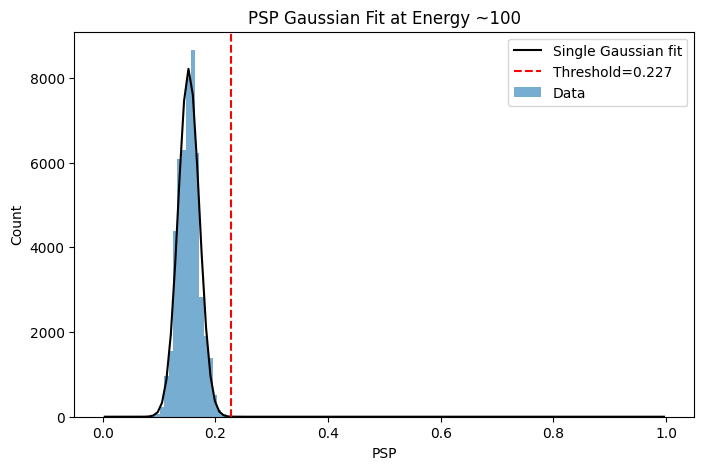

In [16]:
if data_exists("Calibration"):
  psp_threshold = find_psp_threshold_gaussian(psd_data["Calibration"], target_energy=100, num_sigma=4)
else:
  psp_threshold = None
  print("‼️ Calibration data does not exist, cannot perform psp thresold analysis ‼️")


Now that we have our threshold, we can remake the PSD plots to see if there is anything obviously wrong with the analysis.

In [ ]:
if data_exists("Calibration"):
  plot_psd(psd_data["Calibration"], psd_periods["Calibration"], "Calibration", psp_threshold)
else:
  print("‼️ Calibration data does not exist, cannot create PSD plot ‼️")

It can also be instructive to create the PSD plots for the background periods - we would not expect significant changes between the two. Here, we just eyeball them, but performing a statistical analysis will be the next step.

In [ ]:
if data_exists("Background 1") and data_exists("Background 2"):
  fig, axes = plt.subplots(1, 2, figsize=(14, 5), squeeze=False)
  axes = axes.flatten()  # Flatten for easy indexing
  plot_psd(psd_data["Background 1"], psd_periods["Background 1"], 'Background 1', psp_threshold, ax=axes[0])
  plot_psd(psd_data["Background 2"], psd_periods["Background 2"], 'Background 2', psp_threshold, ax=axes[1])
elif data_exists("Background 1"):
  print("Background 2 data does not exist, plotting just Background 1 data")
  plot_psd(psd_data["Background 1"], psd_periods["Background 1"], 'Background 1', psp_threshold)
elif data_exists("Background 2"):
  print("Background 1 data does not exist, plotting just Background 2 data")
  plot_psd(psd_data["Background 2"], psd_periods["Background 2"], 'Background 2', psp_threshold)
else:
  print("‼️ Background data does not exist, cannot create PSD plots ‼️")

/usr/local/lib/python3.12/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


And of course we can look at the experimental period.

In [ ]:
if data_exists("Experiment"):
  plot_psd(psd_data["Experiment"], psd_periods["Experiment"], 'Experiment', psp_threshold=psp_threshold)
else:
  print("‼️ Exeperiment data does not exist, cannot create PSD plot ‼️")

Finally, we now update the master spreadsheet with the PSP threshold that will be used to gamma/neutron discrimination.

In [ ]:
if psp_threshold is not None and "Calibration" in psd_data:
  # Calculate the row number (adjusting for header row)

  row_num = row.index[0] + 2  # +2 because DataFrame index 0 maps to row 2 (header is row 1)
  # Get the column position

  col_position = df.columns.get_loc('psp threshold') + 1  # 1-based column number
  # Update the specific cell

  sheet.update_cell(row_num, col_position, psp_threshold)
  print("Google Sheet updated successfully.")
else:
  print("‼️ No psp threshold has been calculated. Nothing to upload to master sheet.")

Google Sheet updated successfully.


## PSP thresold over time

To detect any detector drift we can perform the same analaysis as above but spit the data into several parts to get psp threshold over time.

In [22]:
def psp_threshold_over_time_period(period_label, n_segments, target_energy=100, num_sigma=4, show_psd_plots=True):
    """
    Calculate PSP thresholds over time for a given experimental period,
    by splitting the period into n_segments and re-querying PSD data for each.

    Parameters
    ----------
    period_label : str
        Name of the period in `psd_periods` / `times` (e.g., "Experiment").
    n_segments : int
        Number of time segments to divide the period into.
    target_energy : float
        Energy to use for PSP threshold calculation (default 100 for Gaussian method).
    num_sigma : float
        Defined psp threshold at the num_sigma*sigma level (default 4 for Gaussian method).
    show_psd_plots : bool
        Whether to show PSD plots for each segment.

    Returns
    -------
    thresholds : list of float
        PSP thresholds for each segment.
    """

    if period_label not in times.columns:
        raise ValueError(f"Period '{period_label}' not found in times table.")

    # Get start and end times from the master times DataFrame
    start_time = times.iloc[0][period_label]
    col_index = list(times.columns).index(period_label)
    for j in range(col_index + 1, len(times.columns)):
        if pd.notna(times.iloc[0, j]):
            end_time = times.iloc[0, j]
            break
    else:
        raise ValueError(f"No end time found for period '{period_label}'")

    total_duration = (end_time - start_time) / n_segments
    thresholds = []
    mid_times = []  # store midpoint times for plotting

    for i in range(n_segments):
        seg_start = start_time + i * total_duration
        seg_end = seg_start + total_duration
        seg_mid = seg_start + total_duration / 2
        mid_times.append(seg_mid)

        seg_data = get_psd_data(seg_start, seg_end)

        if seg_data.empty:
            thresholds.append(np.nan)
            print(f"Segment {i+1} ({seg_start} - {seg_end}): No data")
            continue

        try:
            th = find_psp_threshold_gaussian(
                seg_data,
                target_energy=target_energy,
                num_sigma=num_sigma,
                plot=False
            )
            thresholds.append(th)
            print(f"Segment {i+1} ({seg_start} - {seg_end}): PSP threshold = {th:.4f}")

            if show_psd_plots:
                plt.figure(figsize=(8, 6))
                plot_psd(seg_data, period=None, title=f"Segment {i+1} ({seg_start} - {seg_end})", psp_threshold=th)
                plt.show()

        except ValueError as e:
            thresholds.append(np.nan)
            print(f"Segment {i+1} ({seg_start} - {seg_end}): {e}")

    # Final trend plot using midpoint times
    plt.figure(figsize=(10, 5))
    plt.plot(mid_times, thresholds, marker='o', linestyle='-')
    plt.xlabel("Time")
    plt.ylabel("PSP Threshold (Gaussian drop method)")
    plt.title(f"PSP Threshold Over Time ({period_label})")
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return thresholds


Let's look at the PSD once per day by taking the 14 days of experimental data and performing 14 PSD analyses.

Segment 1 (2025-07-17 13:12:00 - 2025-07-18 13:13:00): PSP threshold = 0.2282
Segment 2 (2025-07-18 13:13:00 - 2025-07-19 13:14:00): PSP threshold = 0.2280
Segment 3 (2025-07-19 13:14:00 - 2025-07-20 13:15:00): PSP threshold = 0.2275
Segment 4 (2025-07-20 13:15:00 - 2025-07-21 13:16:00): PSP threshold = 0.2278
Segment 5 (2025-07-21 13:16:00 - 2025-07-22 13:17:00): PSP threshold = 0.2270
Segment 6 (2025-07-22 13:17:00 - 2025-07-23 13:18:00): PSP threshold = 0.2272
Segment 7 (2025-07-23 13:18:00 - 2025-07-24 13:19:00): PSP threshold = 0.2276
Segment 8 (2025-07-24 13:19:00 - 2025-07-25 13:20:00): PSP threshold = 0.2278
Segment 9 (2025-07-25 13:20:00 - 2025-07-26 13:21:00): PSP threshold = 0.2276
Segment 10 (2025-07-26 13:21:00 - 2025-07-27 13:22:00): PSP threshold = 0.2274
Segment 11 (2025-07-27 13:22:00 - 2025-07-28 13:23:00): PSP threshold = 0.2283
Segment 12 (2025-07-28 13:23:00 - 2025-07-29 13:24:00): PSP threshold = 0.2275
Segment 13 (2025-07-29 13:24:00 - 2025-07-30 13:25:00): PSP t

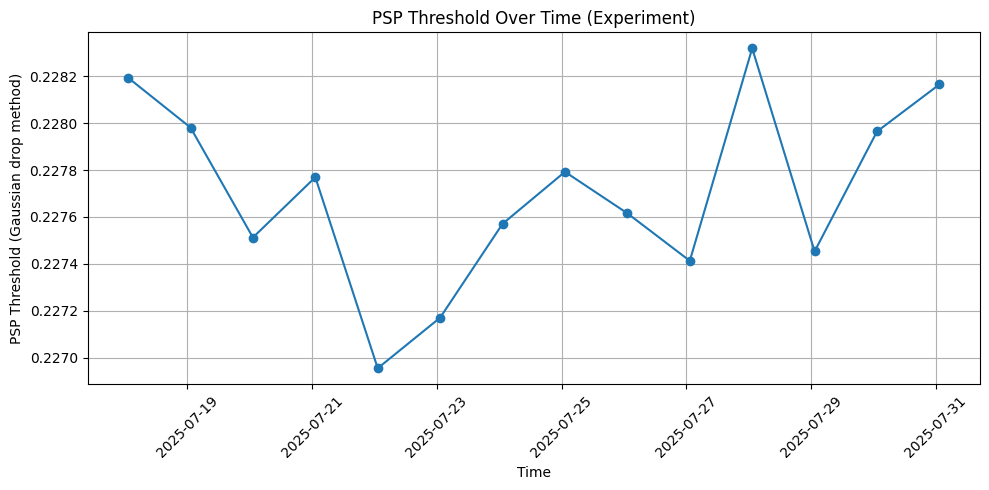

In [27]:
psp_thresholds = psp_threshold_over_time_period("Experiment", 14, show_psd_plots=False)

In [33]:
(np.max(psp_thresholds) - np.min(psp_thresholds))/np.min(psp_thresholds)*100

np.float64(0.6017713629882835)

We can see that the PSP threshold changes by 0.6% across the 14 days.